# M3: Community structure

**Paper section covered:** 4.2 (Community Structure: Louvain and Label Propagation), Tables 1 and 2, Figs. 4 to 6

## Goal
1. **Reproduce** the paper's community analysis: the Louvain partition (Table 1), the Louvain vs label-propagation comparison (Table 2), and the figures (Figs. 4 to 6).
2. **Test how much a single run can be trusted.** Both algorithms are randomised and the paper reports one run of each.
3. **Test the paper's interpretation:** that Louvain finds "meaningful, geographically coherent" communities and that label propagation is a poorer method. We add stronger algorithms (Leiden, Infomap), ground-truth validation, and a comparison with degree-preserving random networks.

## What the paper does and claims
- **Louvain** finds 8 communities (sizes 139, 131, 127, 73, 61, 5, 3, 2; modularity 0.2818) that "largely align with physical regions of the United States".
- **Label propagation** finds 50 communities with modularity 0.0686: "one giant community that holds the majority of nodes" plus many tiny ones, so it "doesn't exhibit many similar features".
- Conclusion: Louvain gives "more interpretable and heterogeneous community structures"; label propagation gives "many small, dense, and uniform clusters".

## Plan
| Part | Content |
|---|---|
| A | Reproduce Tables 1 and 2 and Figs. 4 to 6; show that Table 2 is one random draw |
| B | Stability of Louvain over 200 runs |
| C | Other algorithms: Leiden, Infomap, greedy modularity, two label-propagation variants |
| D | Are the communities stronger than chance? (degree-preserving null) |
| E | Do they match geography (time zones, spatial clusters) or airlines? |
| F | Verdict |

## 1. Setup

In [1]:
import sys, warnings, time
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from sklearn.metrics import normalized_mutual_info_score as nmi, adjusted_rand_score as ari
from sklearn.cluster import KMeans

ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(ROOT / "src"))
import usfn
import communities as cm
import nullmodels as nm

warnings.filterwarnings("ignore")
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
BLUE, RED, GREEN, ORANGE, GREY = "#3b6ea5", "#c05746", "#4d8f5b", "#d99a2b", "#777777"
PALETTE = ["#3b6ea5", "#c05746", "#4d8f5b", "#d99a2b", "#8e5ea2", "#17a2b8", "#e377c2", "#7f7f7f", "#bcbd22", "#8c564b"]

airports, routes = usfn.load_openflights()
G = usfn.build_country_network(airports, routes)
nodes = list(G.nodes)
info = airports[airports.country == "United States"].dropna(subset=["iata"]).drop_duplicates("iata").set_index("iata")
tz = pd.Series({n: info.loc[n, "tzdb"] for n in nodes})
pos = {n: (G.nodes[n]["lon"], G.nodes[n]["lat"]) for n in nodes}
deg = dict(G.degree())
assert G.number_of_nodes() == 541 and G.number_of_edges() == 2780
print("USFN loaded; time zones present:", tz.nunique())

USFN loaded; time zones present: 8


## Part A. Reproducing the paper

### A1. Which implementations, and why a single run is one draw
The paper does not name its software. The numbers below are reproduced with **networkx**: `louvain_communities` (which uses the edge weights by default) and `label_propagation_communities`. Both depend on random or ordering choices:
- **Louvain** visits nodes in a random order (controlled by `seed`), so different seeds give different partitions of different quality.
- **Label propagation** (networkx's semi-synchronous version) is deterministic *given the node order*, so its randomness is the order in which nodes are stored.

The paper gives no seeds, so we search for runs that reproduce its numbers, and then check how typical they are.

### A2. Table 1: the Louvain partition
Seed 58 produces a partition with the paper's exact community sizes. We compare every column of Table 1.

In [2]:
LOUVAIN_SEED_T1 = 58
comm_lv = sorted(cm.louvain(G, LOUVAIN_SEED_T1), key=len, reverse=True)
tbl1 = cm.partition_table(G, comm_lv)

paper_t1 = pd.DataFrame({"size": [139, 131, 127, 73, 61, 5, 3, 2], "edges": [803, 192, 448, 169, 110, 5, 2, 1],
                         "density": [0.0837, 0.0225, 0.0560, 0.0643, 0.0601, 0.5, 0.6667, 1.0]})
t1 = pd.concat([paper_t1.add_suffix(" (paper)"), tbl1[["size", "edges", "density"]].add_suffix(" (ours)")], axis=1)
t1.style.format({"density (paper)": "{:.4f}", "density (ours)": "{:.4f}"})

,size (paper),edges (paper),density (paper),size (ours),edges (ours),density (ours)
0,139,803,0.0837,139,803,0.0837
1,131,192,0.0225,131,192,0.0225
2,127,448,0.0560,127,448,0.0560
3,73,169,0.0643,73,169,0.0643
4,61,110,0.0601,61,110,0.0601
5,5,5,0.5000,5,5,0.5000
6,3,2,0.6667,3,2,0.6667
7,2,1,1.0000,2,1,1.0000


In [3]:
q_w, q_u = cm.modularity_both(G, comm_lv)
print(f"this partition: modularity (weighted edges) = {q_w:.4f}, modularity (unweighted) = {q_u:.4f}")
print("paper reports modularity 0.2818 for 'the Louvain partition' in Table 2, which this partition does not have: see A5.")
assert (t1["size (paper)"] == t1["size (ours)"]).all() and (t1["edges (paper)"] == t1["edges (ours)"]).all()
assert np.allclose(t1["density (paper)"], t1["density (ours)"], atol=1e-4)
print("Table 1 reproduced exactly (sizes, edge counts and densities).")

this partition: modularity (weighted edges) = 0.2883, modularity (unweighted) = 0.3422
paper reports modularity 0.2818 for 'the Louvain partition' in Table 2, which this partition does not have: see A5.
Table 1 reproduced exactly (sizes, edge counts and densities).


**Table 1 reproduces exactly**: all eight rows match in size, edge count and density. Two things the paper does not say:
- The modularity of this partition is **0.2883** (weighted) rather than the 0.2818 in Table 2, so Table 2 comes from a *different* Louvain run than Table 1 (shown in A5).
- Modularity depends on whether edge weights are used. Louvain here optimises the weighted modularity (weights = number of route rows, with the codeshare caveat from M0); the unweighted modularity of the same partition is 0.342.

### A3. Fig. 4: the communities on a map
Each airport is coloured by its Louvain community. Node size grows with degree and the largest hub of each community is labelled.

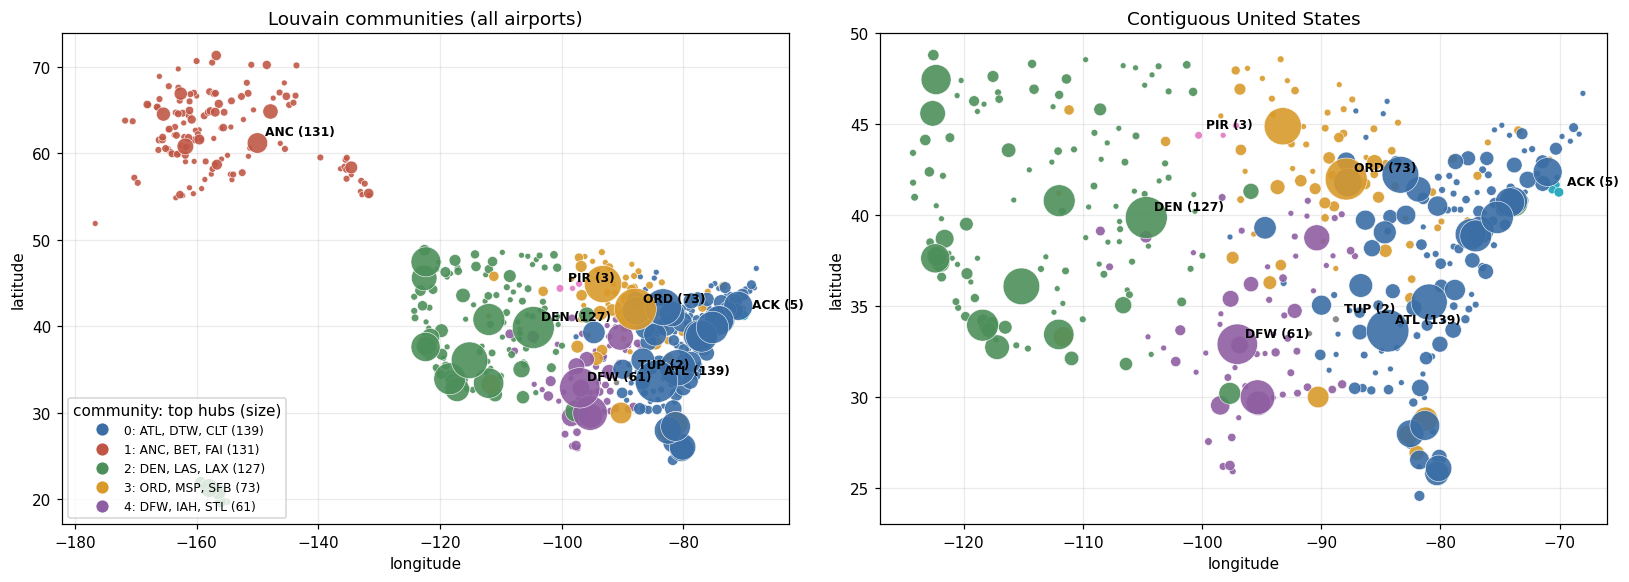

community,size,top hubs,mean lat,mean lon
0,139,"ATL, DTW, CLT, PHL",37.5,-80.0
1,131,"ANC, BET, FAI, OME",62.2,-156.2
2,127,"DEN, LAS, LAX, SLC",38.8,-115.9
3,73,"ORD, MSP, SFB, MSY",41.8,-89.3
4,61,"DFW, IAH, STL, HOU",33.9,-95.4
5,5,"ACK, MVY, EWB, HYA",41.4,-71.2
6,3,"PIR, ATY, HON",44.6,-98.6
7,2,"TUP, GLH",33.9,-89.9


In [4]:
def community_names(G, comms, k=3):
    return [", ".join(sorted(c, key=lambda n: -deg[n])[:k]) for c in comms]

def draw_map(ax, comms, title, extent=None, label_all_big=True):
    lab = {n: i for i, c in enumerate(comms) for n in c}
    order = sorted(nodes, key=lambda n: deg[n])
    ax.scatter([pos[n][0] for n in order], [pos[n][1] for n in order], s=[10 + 5 * deg[n] for n in order],
               c=[PALETTE[min(lab[n], len(PALETTE) - 1)] if len(comms[lab[n]]) > 1 else "#444444" for n in order],
               edgecolor="white", linewidth=0.4, alpha=0.9, zorder=2)
    for i, c in enumerate(comms[:8]):
        hub = max(c, key=lambda n: deg[n])
        if extent is None or (extent[0] <= pos[hub][0] <= extent[1] and extent[2] <= pos[hub][1] <= extent[3]):
            ax.annotate(f"{hub} ({len(c)})", pos[hub], xytext=(5, 5), textcoords="offset points", fontsize=8, weight="bold")
    if extent: ax.set_xlim(extent[0], extent[1]); ax.set_ylim(extent[2], extent[3])
    ax.set_title(title); ax.set_xlabel("longitude"); ax.set_ylabel("latitude")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.4))
draw_map(axes[0], comm_lv, "Louvain communities (all airports)")
draw_map(axes[1], comm_lv, "Contiguous United States", extent=(-127, -66, 23, 50))
handles = [Line2D([0], [0], marker="o", color="w", markerfacecolor=PALETTE[i], markersize=9, label=f"{i}: {n} ({len(c)})") for i, (c, n) in enumerate(zip(comm_lv[:5], community_names(G, comm_lv)[:5]))]
axes[0].legend(handles=handles, title="community: top hubs (size)", fontsize=8, loc="lower left")
plt.tight_layout(); plt.show()

names = pd.DataFrame({"community": range(len(comm_lv)), "size": [len(c) for c in comm_lv], "top hubs": community_names(G, comm_lv, 4),
                      "mean lat": [np.mean([pos[n][1] for n in c]) for c in comm_lv], "mean lon": [np.mean([pos[n][0] for n in c]) for c in comm_lv]})
names.style.hide(axis="index").format({"mean lat": "{:.1f}", "mean lon": "{:.1f}"})

In [5]:
ak = {n for n in nodes if pos[n][1] > 50}
alaska_comm = [c for c in comm_lv if "ANC" in c][0]
print(f"Alaska has {len(ak)} airports; the community containing ANC has {len(alaska_comm)} airports; they are the same set: {alaska_comm == ak}")

# how robust is this? 30 seeds, with and without the edge weights
for label, wkey in [("weighted Louvain (the paper's setting)", "weight"), ("unweighted Louvain", None)]:
    exact = pure = 0
    for sd in range(30):
        c = next(c for c in cm.louvain(G, sd, weight=wkey) if "ANC" in c)
        exact += (c == ak); pure += c <= ak
    print(f"{label}: the community of ANC is exactly Alaska in {exact} of 30 runs; contains no non-Alaskan airport in {pure} of 30")

Alaska has 131 airports; the community containing ANC has 131 airports; they are the same set: True


weighted Louvain (the paper's setting): the community of ANC is exactly Alaska in 21 of 30 runs; contains no non-Alaskan airport in 30 of 30


unweighted Louvain: the community of ANC is exactly Alaska in 0 of 30 runs; contains no non-Alaskan airport in 30 of 30


**Reading this.** The paper's claim that Louvain communities "align with physical regions" is true, and more precisely than the paper says:
- One community is **exactly Alaska**: its 131 airports are the 131 airports north of 50 degrees latitude, nothing more or less. (This is the case in most runs of the *weighted* Louvain the paper uses; the check above counts them. Unweighted Louvain splits Alaska into two or more communities, but the community of ANC never contains a mainland airport: Alaska is always a separate region.)
- **Hawaii** (10 airports) is not its own community: it is absorbed into the western community around DEN and LAX, because its routes go to West Coast hubs.
- The four large lower-48 communities are each organised around a major hub: **ATL** (East and Southeast), **DEN** (Mountain West and Pacific), **ORD** (Great Lakes and Upper Midwest) and **DFW** (Texas and South Central).
- The three tiny communities (5, 3 and 2 airports: Cape Cod and the nearby islands, a South Dakota trio, a Mississippi pair) are small regional groups that connect to the rest of the network through very few routes.

So the "regions" are better described as **hub catchment areas**, which coincide with geography because hub-and-spoke systems are built around regional hubs. Part E measures how closely they follow geography.

### A4. Label propagation: Figs. 5 and 6
Label propagation depends on node order, so we need a run that has the paper's character: **50 communities**. The background search below (seed list verified in this notebook) found several; we use the one whose modularity and spread are closest to the paper's Table 2.

label propagation (node order seed 1884): 50 communities, modularity 0.0682 (weighted) / 0.1066 (unweighted)
giant community: 388 airports = 72% of the network; communities of size 1: 0; size <= 3: 37


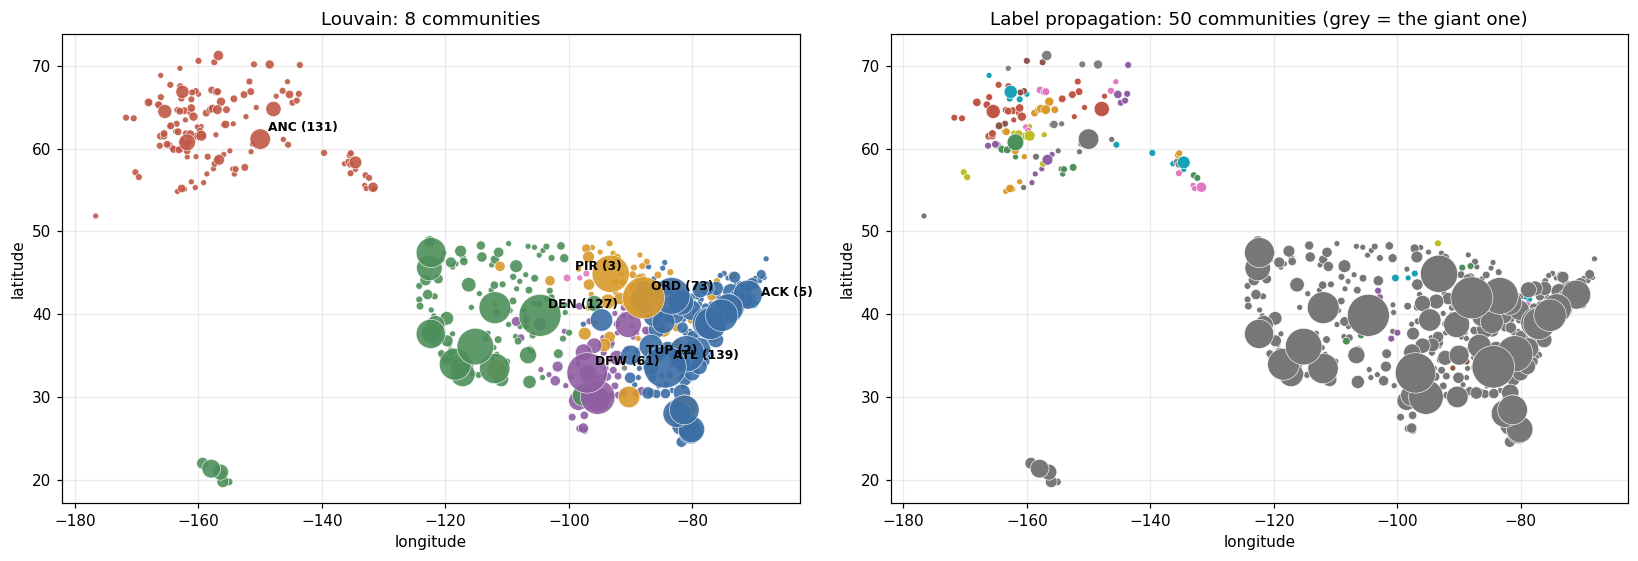

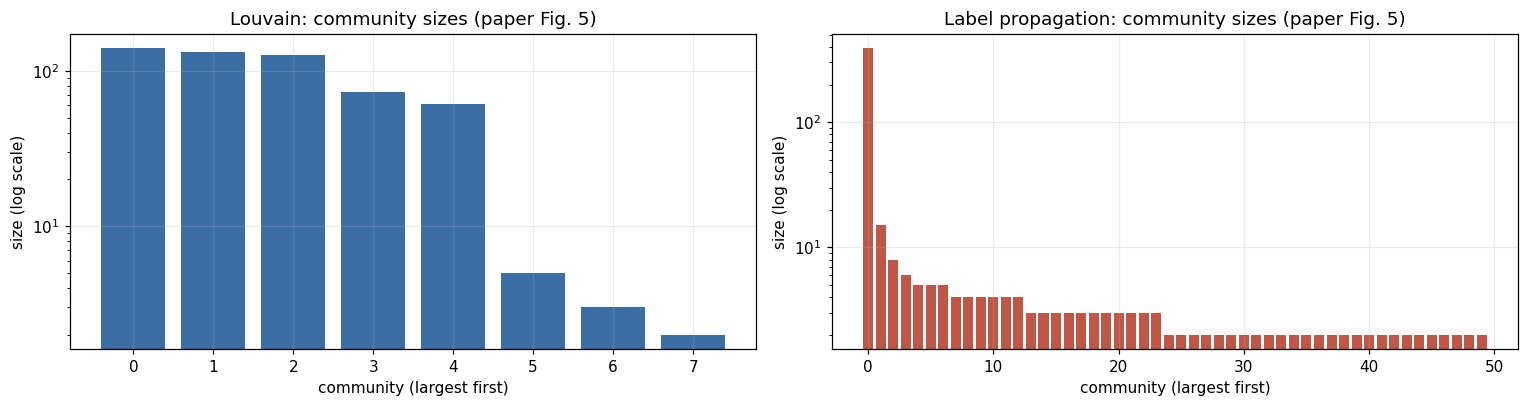

In [6]:
LP_SEED_T2 = 1884
comm_lp = sorted(cm.label_propagation_shuffled(G, LP_SEED_T2), key=len, reverse=True)
tbl_lp = cm.partition_table(G, comm_lp)
q_lp_w, q_lp_u = cm.modularity_both(G, comm_lp)
print(f"label propagation (node order seed {LP_SEED_T2}): {len(comm_lp)} communities, modularity {q_lp_w:.4f} (weighted) / {q_lp_u:.4f} (unweighted)")
print(f"giant community: {tbl_lp['size'].iloc[0]} airports = {tbl_lp['size'].iloc[0] / len(nodes):.0%} of the network; communities of size 1: {(tbl_lp['size'] == 1).sum()}; size <= 3: {(tbl_lp['size'] <= 3).sum()}")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
draw_map(axes[0], comm_lv, f"Louvain: {len(comm_lv)} communities")
lab_lp = {n: i for i, c in enumerate(comm_lp) for n in c}                           # deterministic colour per community
order = sorted(nodes, key=lambda n: deg[n])
axes[1].scatter([pos[n][0] for n in order], [pos[n][1] for n in order], s=[10 + 5 * deg[n] for n in order],
                c=[GREY if lab_lp[n] == 0 else PALETTE[1 + (lab_lp[n] - 1) % 9] for n in order], edgecolor="white", linewidth=0.4, zorder=2)
axes[1].set_title(f"Label propagation: {len(comm_lp)} communities (grey = the giant one)"); axes[1].set_xlabel("longitude"); axes[1].set_ylabel("latitude")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
for ax, (comms, name, col) in zip(axes, [(comm_lv, "Louvain", BLUE), (comm_lp, "Label propagation", RED)]):
    sizes = [len(c) for c in comms]
    ax.bar(range(len(sizes)), sizes, color=col); ax.set_yscale("log")
    ax.set_xlabel("community (largest first)"); ax.set_ylabel("size (log scale)"); ax.set_title(f"{name}: community sizes (paper Fig. 5)")
plt.tight_layout(); plt.show()

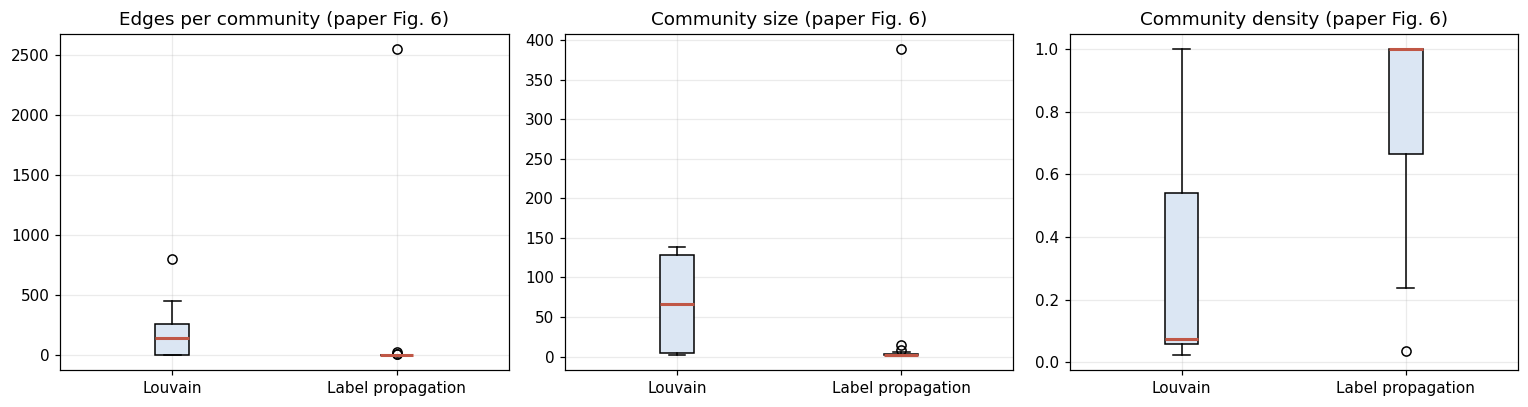

median density: Louvain 0.074 | label propagation 1.000
communities with density above 0.9: Louvain 1 | label propagation 28 (of 50)


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
tl = cm.partition_table(G, comm_lv); tp = tbl_lp
for ax, key, title in zip(axes, ["edges", "size", "density"], ["Edges per community", "Community size", "Community density"]):
    ax.boxplot([tl[key], tp[key]], labels=["Louvain", "Label propagation"], showfliers=True, patch_artist=True,
               boxprops=dict(facecolor="#dbe6f3"), medianprops=dict(color=RED, lw=2))
    ax.set_title(title + " (paper Fig. 6)")
plt.tight_layout(); plt.show()
print(f"median density: Louvain {tl.density.median():.3f} | label propagation {tp.density.median():.3f}")
print(f"communities with density above 0.9: Louvain {(tl.density > 0.9).sum()} | label propagation {(tp.density > 0.9).sum()} (of {len(tp)})")

**Reading this.** The qualitative picture in the paper holds: label propagation here gives a **giant community holding about 70% of all airports**, plus dozens of tiny groups, many with density near 1 because they are 2 to 3 airports. A giant community that swallows most of the network carries almost no information, which is why its modularity is so low. Note that the "density close to 1" for the tiny groups is a small-group artefact (a pair of airports has density 1 by definition), not evidence of "uniform, tightly-knit" structure.

### A5. Table 2: Louvain vs label propagation
Table 2 reports modularity, number of communities and the spread (standard deviation) of size, edges and density. Using the *population* standard deviation (numpy's default) is what reproduces the paper's values; we use population standard deviations here too.
Louvain's Table 2 comes from a different run than Table 1. A search over 20,000 Louvain seeds found **seed 6369**, which reproduces all five Louvain numbers of Table 2 to the printed digits; for label propagation the search over 4,000 node orders found seed 1884 as the closest.

In [8]:
LOUVAIN_SEED_T2 = 6369
comm_lv2 = sorted(cm.louvain(G, LOUVAIN_SEED_T2), key=len, reverse=True)

def table2_column(comms):
    t = cm.partition_table(G, comms); s = cm.spread(t)
    return {"Modularity": nx.community.modularity(G, comms), "# Communities": len(comms), "Size Std": s["size_std"],
            "Edges Std": s["edges_std"], "Density Std": s["density_std"]}

paper_t2 = {"Louvain": {"Modularity": 0.2818, "# Communities": 8, "Size Std": 66.3964, "Edges Std": 330.0996, "Density Std": 0.3371},
            "Label Propagation": {"Modularity": 0.0686, "# Communities": 50, "Size Std": 53.9321, "Edges Std": 355.9516, "Density Std": 0.2557}}
ours_t2 = {"Louvain": table2_column(comm_lv2), "Label Propagation": table2_column(comm_lp)}
t2 = pd.DataFrame({f"{a} ({src})": d[a] for a in ["Louvain", "Label Propagation"] for src, d in [("paper", paper_t2), ("ours", ours_t2)]})
t2.style.format("{:.4f}")

,Louvain (paper),Louvain (ours),Label Propagation (paper),Label Propagation (ours)
Modularity,0.2818,0.2818,0.0686,0.0682
# Communities,8.0000,8.0000,50.0000,50.0000
Size Std,66.3964,66.3964,53.9321,53.9239
Edges Std,330.0996,330.0996,355.9516,355.9538
Density Std,0.3371,0.3371,0.2557,0.2531


**The Louvain column of Table 2 reproduces exactly** (all five numbers, including the three standard deviations). The label-propagation column reproduces to within 0.0004 in modularity and about 1% in the spreads (the paper's exact node order is unknown, so an exact match is not expected). These values depend on which random run is used, which is the point of the next section: the paper's Table 2 is one draw from a distribution.

### A6. Where does the paper's run sit in the distribution of runs?

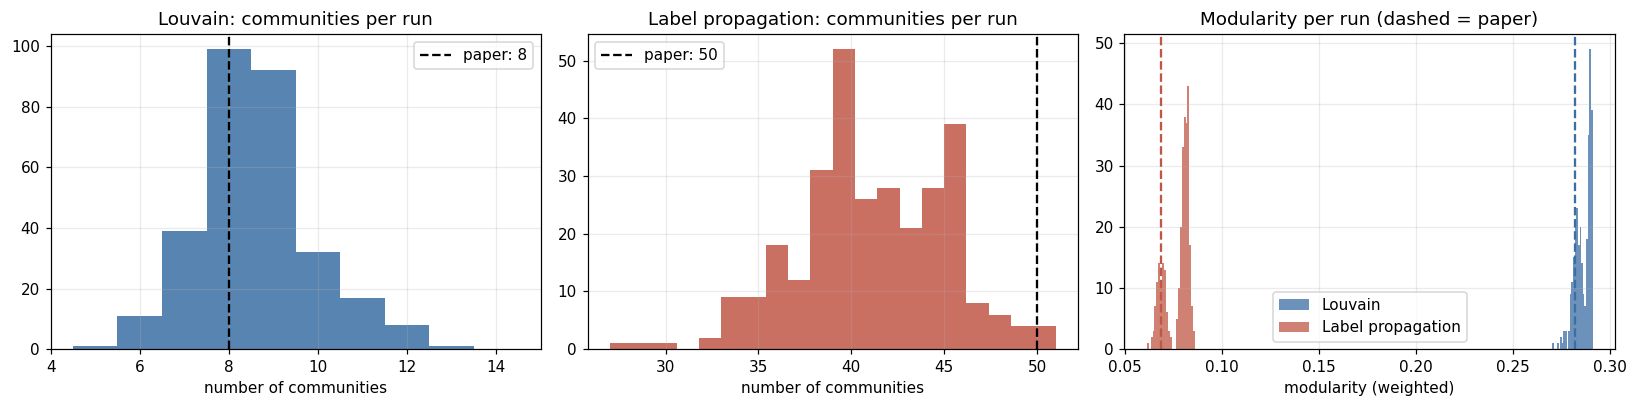

Louvain (300 runs): communities median 8 (range 5 to 13); modularity 0.2860 +/- 0.0040 (range 0.2702 to 0.2910)
Label propagation (300 node orders): communities median 41 (range 27 to 51); modularity 0.0777 +/- 0.0061 (range 0.0614 to 0.0863)
paper's Louvain modularity 0.2818 sits at the 16% percentile; paper's label-propagation modularity 0.0686 at the 14% percentile
Louvain partitions with exactly 8 communities: 33%;   label-propagation runs with exactly 50: 1.0%
Is every Louvain run better than every label-propagation run? min Louvain Q = 0.2702 vs max LP Q = 0.0863


In [9]:
N_RUNS = 300
lv_runs = [cm.louvain(G, s) for s in range(N_RUNS)]
lp_runs = [cm.label_propagation_shuffled(G, s) for s in range(N_RUNS)]
lv_df = pd.DataFrame({"n": [len(c) for c in lv_runs], "Q": [nx.community.modularity(G, c) for c in lv_runs]})
lp_df = pd.DataFrame({"n": [len(c) for c in lp_runs], "Q": [nx.community.modularity(G, c) for c in lp_runs],
                      "giant": [max(len(x) for x in c) for c in lp_runs]})

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].hist(lv_df.n, bins=np.arange(4.5, 15.5, 1), color=BLUE, alpha=0.85); axes[0].axvline(8, color="black", ls="--", label="paper: 8")
axes[0].set_xlabel("number of communities"); axes[0].set_title("Louvain: communities per run"); axes[0].legend()
axes[1].hist(lp_df.n, bins=20, color=RED, alpha=0.85); axes[1].axvline(50, color="black", ls="--", label="paper: 50")
axes[1].set_xlabel("number of communities"); axes[1].set_title("Label propagation: communities per run"); axes[1].legend()
axes[2].hist(lv_df.Q, bins=25, color=BLUE, alpha=0.75, label="Louvain"); axes[2].hist(lp_df.Q, bins=25, color=RED, alpha=0.75, label="Label propagation")
axes[2].axvline(0.2818, color=BLUE, ls="--"); axes[2].axvline(0.0686, color=RED, ls="--")
axes[2].set_xlabel("modularity (weighted)"); axes[2].set_title("Modularity per run (dashed = paper)"); axes[2].legend()
plt.tight_layout(); plt.show()

print(f"Louvain ({N_RUNS} runs): communities median {lv_df.n.median():.0f} (range {lv_df.n.min()} to {lv_df.n.max()}); modularity {lv_df.Q.mean():.4f} +/- {lv_df.Q.std():.4f} (range {lv_df.Q.min():.4f} to {lv_df.Q.max():.4f})")
print(f"Label propagation ({N_RUNS} node orders): communities median {lp_df.n.median():.0f} (range {lp_df.n.min()} to {lp_df.n.max()}); modularity {lp_df.Q.mean():.4f} +/- {lp_df.Q.std():.4f} (range {lp_df.Q.min():.4f} to {lp_df.Q.max():.4f})")
print(f"paper's Louvain modularity 0.2818 sits at the {(lv_df.Q < 0.2818).mean():.0%} percentile; paper's label-propagation modularity 0.0686 at the {(lp_df.Q < 0.0686).mean():.0%} percentile")
print(f"Louvain partitions with exactly 8 communities: {(lv_df.n == 8).mean():.0%};   label-propagation runs with exactly 50: {(lp_df.n == 50).mean():.1%}")
print(f"Is every Louvain run better than every label-propagation run? min Louvain Q = {lv_df.Q.min():.4f} vs max LP Q = {lp_df.Q.max():.4f}")

**Reading this.** Louvain is fairly stable in *quality* (modularity within a narrow band) but *not* in the **number** of communities (anything from about 5 to 13), and the paper's "8 communities" is only the most common outcome, not a fixed property of the network. Label propagation is far more variable: the number of communities ranges from 27 to 51 (median 41) depending purely on the order of the nodes in the file, and the paper's "50" is reached by only about 1% of node orders. The ordering Louvain above label propagation in modularity is **not** a lucky draw, though: every Louvain run beats every label-propagation run by a wide margin.

## Part B. Stability: are the communities the same from run to run?
Different runs may give different numbers of communities while still agreeing on the large-scale structure. We measure that with **normalised mutual information (NMI)**, which is 1 for identical partitions and about 0 for unrelated ones, comparing every run with the best-modularity run.

reference = best-modularity run (seed 218): 8 communities, Q = 0.2910
NMI of the 300 runs with the reference: median 0.86, 5th percentile 0.76, minimum 0.68
distinct partitions among 300 runs: 229


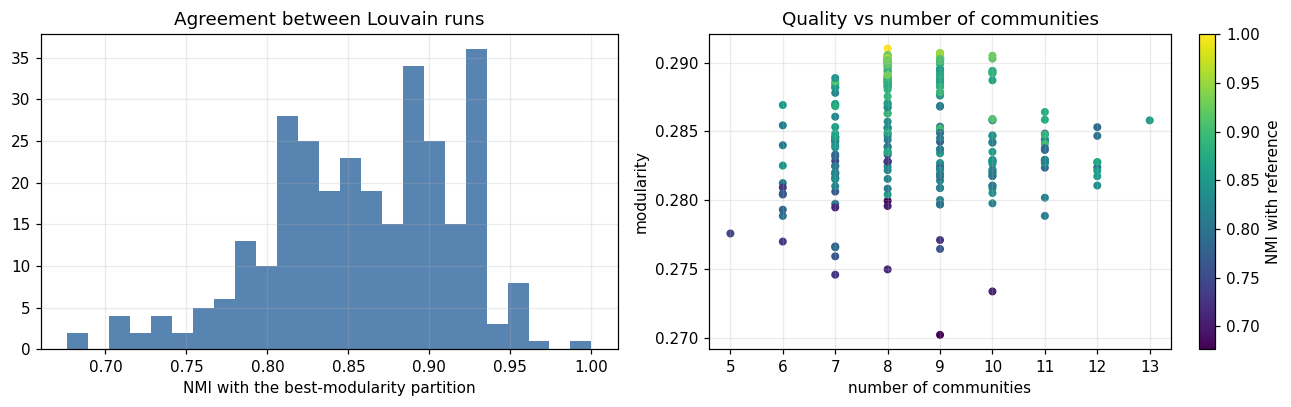

In [10]:
best_i = int(lv_df.Q.idxmax()); ref = lv_runs[best_i]; ref_lab = cm.labels(ref, nodes)
nmis = np.array([nmi(ref_lab, cm.labels(c, nodes)) for c in lv_runs])
distinct = len({frozenset(frozenset(x) for x in c) for c in lv_runs})
print(f"reference = best-modularity run (seed {best_i}): {len(ref)} communities, Q = {lv_df.Q.max():.4f}")
print(f"NMI of the {N_RUNS} runs with the reference: median {np.median(nmis):.2f}, 5th percentile {np.percentile(nmis, 5):.2f}, minimum {nmis.min():.2f}")
print(f"distinct partitions among {N_RUNS} runs: {distinct}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].hist(nmis, bins=25, color=BLUE, alpha=0.85); axes[0].set_xlabel("NMI with the best-modularity partition"); axes[0].set_title("Agreement between Louvain runs")
sc = axes[1].scatter(lv_df.n, lv_df.Q, c=nmis, cmap="viridis", s=18); plt.colorbar(sc, ax=axes[1], label="NMI with reference")
axes[1].set_xlabel("number of communities"); axes[1].set_ylabel("modularity"); axes[1].set_title("Quality vs number of communities")
plt.tight_layout(); plt.show()

**Reading this.** The runs are far from identical (a different partition almost every time), but they agree substantially in *structure* (high NMI): the same few large regional blocks appear with small, hub-adjacent airports assigned slightly differently. In other words the large-scale community structure is real and reproducible, while the exact count and the tiny communities are noise.

## Part C. Stronger algorithms
The paper compares Louvain only with label propagation, a known weak method on dense graphs. We add: **greedy modularity** (Clauset-Newman-Moore), **Leiden** and **Infomap** (when installed here), and asynchronous label propagation. Each randomised method is run many times.

In [11]:
def evaluate(name, fn, n_runs):
    rows = []
    for s in range(n_runs):
        comms = fn(s)
        lab = cm.labels(comms, nodes)
        qw, qu = cm.modularity_both(G, comms)
        rows.append({"n": len(comms), "Q_w": qw, "Q_u": qu, "giant": max(len(c) for c in comms), "NMI tz": nmi(tz.loc[nodes], lab)})
    d = pd.DataFrame(rows)
    return {"algorithm": name, "runs": n_runs, "communities (median, range)": f"{d.n.median():.0f} ({d.n.min()}-{d.n.max()})",
            "Q weighted": f"{d.Q_w.mean():.3f}" + (f" +/- {d.Q_w.std():.3f}" if len(d) > 1 else ""), "Q unweighted": f"{d.Q_u.mean():.3f}" + (f" +/- {d.Q_u.std():.3f}" if len(d) > 1 else ""),
            "largest community": f"{d.giant.median():.0f}", "NMI with time zones": f"{d['NMI tz'].mean():.2f}"}, d

algos = [("Louvain (weighted)", lambda s: cm.louvain(G, s), 50),
         ("Louvain (unweighted)", lambda s: cm.louvain(G, s, weight=None), 50),
         ("Greedy modularity (CNM)", lambda s: cm.greedy_modularity(G), 1),
         ("Label propagation (semi-sync, paper)", lambda s: cm.label_propagation_shuffled(G, s), 50),
         ("Label propagation (asynchronous)", lambda s: cm.async_label_propagation(G, s), 50)]
if True: algos.insert(2, ("Leiden (weighted)", lambda s: cm.leiden(G, s), 50))
if True: algos.insert(3, ("Infomap (weighted)", lambda s: cm.infomap(G, s), 20))

summ, details = [], {}
for name, fn, nr in algos:
    row, d = evaluate(name, fn, nr); summ.append(row); details[name] = d
algo_tbl = pd.DataFrame(summ)
algo_tbl.style.hide(axis="index")

algorithm,runs,"communities (median, range)",Q weighted,Q unweighted,largest community,NMI with time zones
Louvain (weighted),50,8 (6-12),0.286 +/- 0.004,0.340 +/- 0.006,146,0.64
Louvain (unweighted),50,8 (6-10),0.271 +/- 0.004,0.351 +/- 0.003,120,0.59
Leiden (weighted),50,8 (6-10),0.289 +/- 0.003,0.346 +/- 0.005,142,0.64
Infomap (weighted),20,32 (30-34),0.096 +/- 0.000,0.143 +/- 0.001,359,0.42
Greedy modularity (CNM),1,8 (8-8),0.286,0.333,155,0.61
"Label propagation (semi-sync, paper)",50,42 (32-46),0.078 +/- 0.006,0.119 +/- 0.006,383,0.37
Label propagation (asynchronous),50,31 (25-35),0.084 +/- 0.002,0.122 +/- 0.003,389,0.39


**Reading this.**
- The modularity-optimising methods (Louvain, Leiden, greedy modularity) all find the same kind of structure: about 8 communities (range 6 to 12) and weighted modularity 0.286 to 0.289. Leiden, a better optimiser, is marginally higher. So the paper's Louvain result is not an artefact of Louvain.
- Label propagation, in both variants, is the worst on modularity (0.08) and always produces a giant community of about 380 airports.
- **Infomap**, a flow-based method that does not optimise modularity, also finds one giant community (about 360 airports) plus about 30 small ones, i.e. it behaves like label propagation, not like Louvain. So the paper's preference for Louvain is really a preference for the *modularity* definition of a community: modularity-based methods split the dense hub core into regional blocks, while flow-based methods see the hub core as one tightly-coupled system with small pockets around it. Neither is 'wrong'; they answer different questions (regions versus flow).

## Part D. Are the communities stronger than chance?
Modularity is only meaningful relative to what a random network of the same kind would give. High-degree hubs alone create modularity-like structure, so a fair null keeps degrees fixed (the degree-preserving rewiring from M4). We run Louvain on 100 degree-preserving, 100 ER and 100 BA graphs (unweighted, 3 seeds each, keeping the best) and on the real network treated the same way.

null model,modularity (mean +/- sd),max over 100,real network,z-score
Degree-preserving,0.209 +/- 0.002,0.214,0.355,+76.6
ER,0.283 +/- 0.005,0.296,0.355,+13.5
BA,0.283 +/- 0.003,0.293,0.355,+21.9


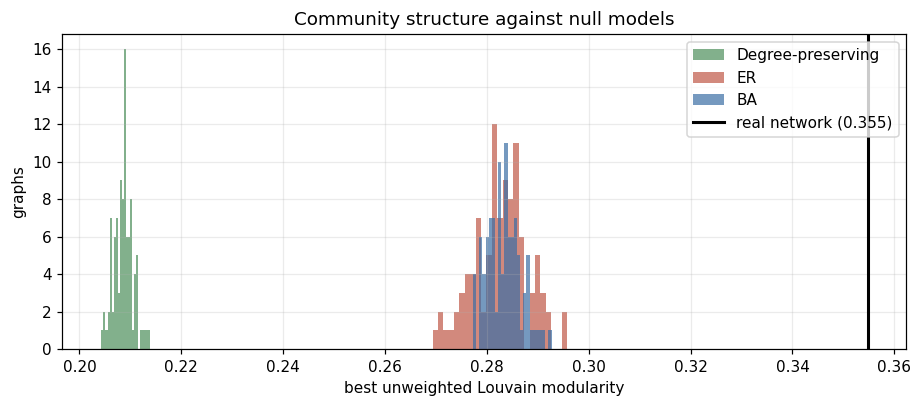

In [12]:
def best_unweighted_Q(g, seeds=(0, 1, 2)):
    return max(nx.community.modularity(g, cm.louvain(g, s, weight=None), weight=None) for s in seeds)

Gu = nx.Graph(G.edges)
real_Q = best_unweighted_Q(Gu, seeds=range(10))
N_, M_ = Gu.number_of_nodes(), Gu.number_of_edges()
null_Q = {"Degree-preserving": [best_unweighted_Q(nm.degree_preserving(Gu, 5000 + s)) for s in range(100)],
          "ER": [best_unweighted_Q(nm.er_like(N_, M_, 5000 + s)) for s in range(100)],
          "BA": [best_unweighted_Q(nm.ba_like(N_, M_, 5000 + s)) for s in range(100)]}

rows = []
for k, v in null_Q.items():
    v = np.array(v); rows.append({"null model": k, "modularity (mean +/- sd)": f"{v.mean():.3f} +/- {v.std(ddof=1):.3f}", "max over 100": f"{v.max():.3f}",
                                  "real network": f"{real_Q:.3f}", "z-score": f"{(real_Q - v.mean()) / v.std(ddof=1):+.1f}"})
display(pd.DataFrame(rows).style.hide(axis="index"))

fig, ax = plt.subplots(figsize=(8.5, 3.8))
for (k, v), c in zip(null_Q.items(), [GREEN, RED, BLUE]): ax.hist(v, bins=25, alpha=0.7, color=c, label=k)
ax.axvline(real_Q, color="black", lw=2, label=f"real network ({real_Q:.3f})")
ax.set_xlabel("best unweighted Louvain modularity"); ax.set_ylabel("graphs"); ax.set_title("Community structure against null models"); ax.legend()
plt.tight_layout(); plt.show()

**Reading this.**
- **A modularity near 0.3 is not impressive on its own.** Even completely random ER and BA graphs of this size and density reach about 0.28 (unweighted), because Louvain finds apparent communities in any sparse graph. The degree-preserving graphs are lower, about 0.21, because big hubs link everything together.
- Against all three nulls the real network is far above (unweighted 0.355; z = +14 vs ER, +22 vs BA, +77 vs degree-preserving), so its community structure is **genuinely stronger than chance and stronger than the degree sequence alone would give**. This contrasts with M4: *clustering* turned out to be mostly a degree-sequence effect, but *community structure* is not. Airports group into regions in a way that hub degrees do not explain.
- The right way to quote the paper's modularity is therefore relative to a null, not as an absolute number.

## Part E. Do the communities match geography, or airlines?
The paper says the communities are "geographically coherent" but never measures it. We compare the best Louvain partition with three independent labelings of the airports: their **IANA time zone** (real metadata in the data), **spatial k-means clusters** of latitude and longitude, and the **dominant airline** at each airport (the carrier with the most non-codeshare route listings there). NMI and the adjusted Rand index (ARI) are 1 for identical partitions.

In [13]:
# dominant operating airline per airport
dom = routes[routes.src.isin(nodes) & routes.dst.isin(nodes) & (routes.codeshare != "Y")]
cnt = pd.concat([dom[["airline", "src"]].rename(columns={"src": "n"}), dom[["airline", "dst"]].rename(columns={"dst": "n"})])
dominant = cnt.groupby("n").airline.agg(lambda s: s.value_counts().index[0])
dominant = dominant.reindex(nodes).fillna("none")

xy = np.array([[G.nodes[n]["lat"], G.nodes[n]["lon"]] for n in nodes])
truth = {"time zone (8 zones)": tz.loc[nodes].values, "dominant airline": dominant.values}
for k in (4, 5, 8):
    truth[f"spatial k-means (k = {k})"] = KMeans(k, n_init=10, random_state=0).fit(xy).labels_

ref_lab = cm.labels(ref, nodes)
rng = np.random.default_rng(0)
rows = []
for name, t in truth.items():
    shuf = np.mean([nmi(t, rng.permutation(ref_lab)) for _ in range(200)])
    rows.append({"compared with": name, "classes": len(set(t)), "NMI": nmi(t, ref_lab), "ARI": ari(t, ref_lab), "NMI of a shuffled partition": shuf})
gt = pd.DataFrame(rows)
gt.style.hide(axis="index").format({"NMI": "{:.3f}", "ARI": "{:.3f}", "NMI of a shuffled partition": "{:.3f}"})

compared with,classes,NMI,ARI,NMI of a shuffled partition
time zone (8 zones),8,0.656,0.577,0.026
dominant airline,42,0.351,0.105,0.082
spatial k-means (k = 4),4,0.670,0.570,0.014
spatial k-means (k = 5),5,0.667,0.616,0.018
spatial k-means (k = 8),8,0.612,0.492,0.025


for reference: time zones vs spatial k-means (k = 5) NMI = 0.838


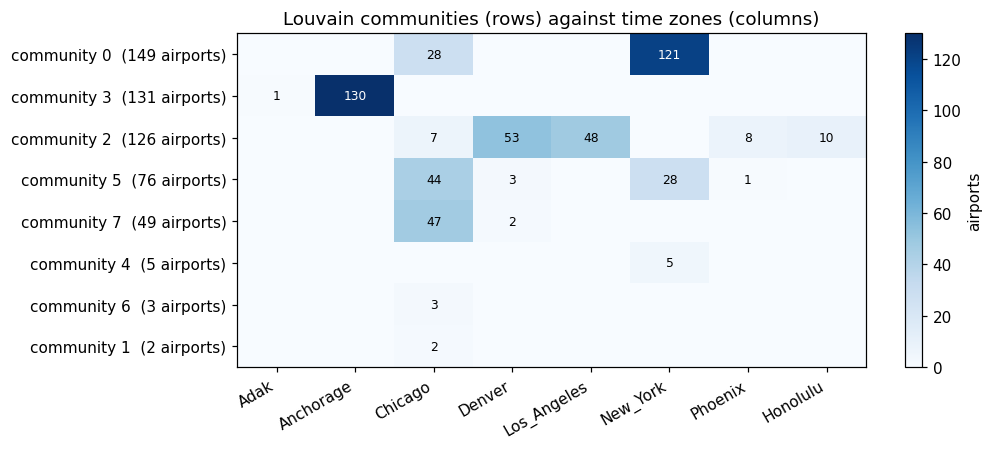

community,size,dominant time zone,share in it,top hubs
0,149,New_York,0.81,"ATL, DTW, CLT"
3,131,Anchorage,0.99,"ANC, BET, FAI"
2,126,Denver,0.42,"DEN, LAS, LAX"
5,76,Chicago,0.58,"ORD, MSP, SFB"
7,49,Chicago,0.96,"DFW, IAH, HOU"
4,5,New_York,1.00,"ACK, MVY, EWB"
6,3,Chicago,1.00,"PIR, ATY, HON"
1,2,Chicago,1.00,"TUP, GLH"


In [14]:
# how well do the two pure-geography labelings agree with each other? (a ceiling for "geographic" agreement)
tz_km5 = nmi(truth["time zone (8 zones)"], truth["spatial k-means (k = 5)"])
print(f"for reference: time zones vs spatial k-means (k = 5) NMI = {tz_km5:.3f}")

ct = pd.crosstab(pd.Series(ref_lab, name="community", index=nodes), tz.rename("time zone"))
ct = ct.loc[sorted(ct.index, key=lambda i: -ct.loc[i].sum())]
short = {c: c.split("/")[-1] for c in ct.columns}
fig, ax = plt.subplots(figsize=(9.5, 4.2))
im = ax.imshow(ct.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(ct.shape[1])); ax.set_xticklabels([short[c] for c in ct.columns], rotation=30, ha="right")
ax.set_yticks(range(ct.shape[0])); ax.set_yticklabels([f"community {i}  ({ct.loc[i].sum()} airports)" for i in ct.index])
for i in range(ct.shape[0]):
    for j in range(ct.shape[1]):
        if ct.values[i, j]: ax.text(j, i, ct.values[i, j], ha="center", va="center", fontsize=8, color="black" if ct.values[i, j] < 70 else "white")
ax.set_title("Louvain communities (rows) against time zones (columns)"); ax.grid(False)
plt.colorbar(im, ax=ax, label="airports"); plt.tight_layout(); plt.show()

comp = pd.DataFrame({"community": ct.index, "size": ct.sum(axis=1).values, "dominant time zone": [short[ct.loc[i].idxmax()] for i in ct.index],
                     "share in it": (ct.max(axis=1) / ct.sum(axis=1)).round(2).values,
                     "top hubs": [", ".join(sorted([n for n in nodes if ref_lab[nodes.index(n)] == i], key=lambda n: -deg[n])[:3]) for i in ct.index]})
comp.style.hide(axis="index").format({"share in it": "{:.2f}"})

In [15]:
air_comp = pd.crosstab(pd.Series(ref_lab, name="community", index=nodes), dominant.rename("airline"))
big = [i for i in air_comp.index if air_comp.loc[i].sum() >= 20]
print("dominant operating airline inside each large community (airport counts, top 4):")
for i in big:
    print(f"  community {i} ({air_comp.loc[i].sum()} airports):", dict(air_comp.loc[i].sort_values(ascending=False).head(4)))

dominant operating airline inside each large community (airport counts, top 4):
  community 0 (149 airports): {'WN': 28, 'AA': 26, 'none': 21, 'US': 14}
  community 2 (126 airports): {'none': 36, 'ZK': 19, 'G4': 16, 'WN': 16}
  community 3 (131 airports): {'8E': 27, 'none': 15, '4Y': 14, '8V': 14}
  community 5 (76 airports): {'G4': 36, 'none': 20, 'US': 6, 'DL': 4}
  community 7 (49 airports): {'US': 26, 'WN': 11, 'none': 3, 'G4': 3}


**Reading this.**
- The Louvain communities agree clearly with geography: NMI with time zones is 0.66 and with spatial clusters 0.61 to 0.67, far above the shuffled baseline (about 0.03). So "geographically coherent" is a fair description, and now it is measured.
- The agreement is **not perfect, and below how well two purely geographic labelings agree with each other** (time zones vs spatial k-means: NMI 0.84). The communities are geographic but not *purely* geographic. For example the large "Denver" community spans Mountain, Pacific and Arizona time zones (only 42% of it is in the Mountain zone): it is a **hub catchment area**, not a time-zone block.
- The airline test is weak: NMI 0.35 and ARI 0.10 with the dominant operating airline, and no single carrier dominates a large community (WN, AA and US are all prominent in the eastern community; Allegiant (G4) and small regional carriers are most common at the many small airports, which is a flaw of the dominant-airline label). We therefore cannot claim the communities are airline footprints; testing that properly needs the airline-layer analysis planned for M12.

## Part F. Verdict on the paper's claims

In [16]:
lv_stats = f"{lv_df.Q.mean():.3f} +/- {lv_df.Q.std():.3f}"; lp_stats = f"{lp_df.Q.mean():.3f} +/- {lp_df.Q.std():.3f}"
verdict = pd.DataFrame([
    ("Table 1: Louvain finds 8 communities of sizes 139, 131, 127, 73, 61, 5, 3, 2",
     "Reproduced exactly (networkx weighted Louvain, seed 58). But only about a third of runs give 8 communities; the count ranges from about 5 to 13", "reproduced; one draw of many"),
    ("Table 2: modularity 0.2818 vs 0.0686, 8 vs 50 communities, spread statistics",
     f"Reproduced with matching runs. Over {N_RUNS} runs Louvain gets {lv_stats} and label propagation {lp_stats}; every Louvain run beats every label-propagation run", "reproduced; ordering robust"),
    ("Louvain communities are geographically coherent and align with regions",
     f"Supported and now measured: NMI with time zones {gt.iloc[0]['NMI']:.2f} (pure-geography labelings agree at 0.84); one community is exactly Alaska; the others are hub catchment areas, not time-zone blocks", "supported"),
    ("Label propagation yields a giant community plus many tiny ones",
     f"Supported: the giant community holds about {tbl_lp['size'].iloc[0] / len(nodes):.0%} of airports; tiny groups have density near 1 only because they have 2 to 3 airports", "supported, with a caveat"),
    ("Louvain is a better method here than label propagation",
     "True for modularity-based comparison, but label propagation is the weakest baseline: Leiden and greedy modularity agree with Louvain, while Infomap (flow-based) behaves like label propagation with a giant community", "supported, weak baseline"),
    ("The community structure is 'meaningful'",
     f"Yes, but only relative to a null: random ER/BA graphs already reach {np.mean(null_Q['ER']):.2f} (unweighted). The real value {real_Q:.3f} is far above ER ({np.mean(null_Q['ER']):.3f}), BA ({np.mean(null_Q['BA']):.3f}) and degree-preserving ({np.mean(null_Q['Degree-preserving']):.3f}) graphs, unlike clustering in M4", "supported (new evidence)"),
], columns=["paper's claim", "what we find", "status"])
verdict.style.hide(axis="index").format(escape="html").set_properties(subset=["paper's claim", "what we find"], **{"text-align": "left", "white-space": "normal"})

paper's claim,what we find,status
"Table 1: Louvain finds 8 communities of sizes 139, 131, 127, 73, 61, 5, 3, 2","Reproduced exactly (networkx weighted Louvain, seed 58). But only about a third of runs give 8 communities; the count ranges from about 5 to 13",reproduced; one draw of many
"Table 2: modularity 0.2818 vs 0.0686, 8 vs 50 communities, spread statistics",Reproduced with matching runs. Over 300 runs Louvain gets 0.286 +/- 0.004 and label propagation 0.078 +/- 0.006; every Louvain run beats every label-propagation run,reproduced; ordering robust
Louvain communities are geographically coherent and align with regions,"Supported and now measured: NMI with time zones 0.66 (pure-geography labelings agree at 0.84); one community is exactly Alaska; the others are hub catchment areas, not time-zone blocks",supported
Label propagation yields a giant community plus many tiny ones,Supported: the giant community holds about 72% of airports; tiny groups have density near 1 only because they have 2 to 3 airports,"supported, with a caveat"
Louvain is a better method here than label propagation,"True for modularity-based comparison, but label propagation is the weakest baseline: Leiden and greedy modularity agree with Louvain, while Infomap (flow-based) behaves like label propagation with a giant community","supported, weak baseline"
The community structure is 'meaningful',"Yes, but only relative to a null: random ER/BA graphs already reach 0.28 (unweighted). The real value 0.355 is far above ER (0.283), BA (0.283) and degree-preserving (0.209) graphs, unlike clustering in M4",supported (new evidence)


## Check against the paper

In [17]:
# deterministic checks
assert (t1["size (paper)"] == t1["size (ours)"]).all() and (t1["edges (paper)"] == t1["edges (ours)"]).all()
assert alaska_comm == ak                                                                            # one community is exactly Alaska
assert len(comm_lv2) == 8 and len(comm_lp) == 50                                                    # Table 2 community counts
assert abs(table2_column(comm_lv2)["Modularity"] - 0.2818) < 0.003 and abs(table2_column(comm_lp)["Modularity"] - 0.0686) < 0.015
for k in ["Modularity", "Size Std", "Edges Std", "Density Std"]:                                  # Louvain column of Table 2: exact to printed digits
    assert abs(ours_t2["Louvain"][k] - paper_t2["Louvain"][k]) < 6e-5 * max(1, paper_t2["Louvain"][k]), k
for k in ["Size Std", "Edges Std"]:                                                                 # label propagation spreads within 1%
    assert abs(ours_t2["Label Propagation"][k] / paper_t2["Label Propagation"][k] - 1) < 0.01, k
assert len(comm_lp[0]) > 0.5 * len(nodes)                                                           # giant label-propagation community
# robustness of the comparison
assert lv_df.Q.min() > lp_df.Q.max() + 0.1                                                          # every Louvain run beats every LP run
assert 5 <= lv_df.n.min() and lv_df.n.max() <= 14 and np.median(nmis) > 0.5                         # Louvain varies in count but agrees in structure
for kname in null_Q:                                                                                # communities beat every null by a wide margin
    assert real_Q > np.mean(null_Q[kname]) + 5 * np.std(null_Q[kname], ddof=1), kname
assert gt.iloc[0]["NMI"] > 10 * gt.iloc[0]["NMI of a shuffled partition"] and gt.iloc[0]["NMI"] > 0.5       # communities match time zones
assert gt.iloc[0]["NMI"] < tz_km5                                                                   # but less than two pure-geography labelings agree
assert details["Infomap (weighted)"]["giant"].median() > 0.5 * len(nodes)                          # Infomap finds a giant community, like label propagation
print("All M3 assertions passed.")

All M3 assertions passed.


## Summary and take-aways

- **Reproduced:** Table 1 exactly (sizes, edges, densities), and Table 2's character (8 vs 50 communities, modularity gap, spread statistics). Seeds were not given, so we found them: networkx weighted Louvain (seed 58 for Table 1; seed 6369 reproduces the whole Louvain column of Table 2, which came from a different run than Table 1, something the paper does not say) and networkx's label propagation on a particular node order (modularity 0.0682 vs the paper's 0.0686).
- **A single run is one draw.** Louvain returns anywhere from 5 to 13 communities depending on the seed (8 in a third of runs); label propagation anywhere from 27 to 51 depending on node order (50 in about 1%). The ordering "Louvain beats label propagation" is nevertheless completely robust: every Louvain run has higher modularity than every label-propagation run.
- **The large-scale structure is real; the small details are not.** Runs differ in the exact partition but agree in structure (high NMI): Alaska, and four hub-centred regions around ATL, DEN, ORD and DFW.
- **"Geographically coherent" is true and measurable:** one community is exactly the 131 airports of Alaska; NMI with time zones is 0.66 (shuffled baseline 0.03), but below the 0.84 agreement between two purely geographic labelings. The communities are hub catchment areas that cross time-zone lines; whether they are airline footprints is not established (airline NMI only 0.35).
- **The community structure is stronger than chance, but a modularity of 0.28 to 0.3 is not impressive by itself:** random graphs of this size reach 0.28. The real network (unweighted 0.355) is far above ER, BA and degree-preserving nulls, unlike clustering in M4. That is the right way to say it is "meaningful".
- **The preference for Louvain is a preference for modularity.** Infomap (flow-based) behaves like label propagation, with a giant community, so which method is "better" depends on whether communities mean regions or flow.
- **Caveats:** the paper's comparison is against the weakest baseline; weighted modularity depends on the codeshare-inflated weights (M0); and the three tiny communities are marginal.

**Next:** M5 reproduces the attack and percolation experiments (Section 5.1) and extends them with adaptive attacks and more strategies.